In this notebook a Deep Embedding Clustiring approach is tried. A naive run of the Kernel-bounded clustering is runned as well.

# 00 - General operations

In [1]:
from tqdm import tqdm
import csv
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd 

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, normalized_mutual_info_score, adjusted_rand_score
from sklearn.preprocessing import PowerTransformer

from scipy.optimize import linear_sum_assignment

import os
import time

import tensorflow as tf
import keras 
import keras.backend as K
from keras import ops

import sys
from pathlib import Path
sys.path.append(str(Path("../../src/utils").resolve()))
from dataset_balancing import balance_dataset
sys.path.append(str(Path("../../src/models").resolve()))
from autoencoder import AutoEncoder

Set the random seed for reproducibility:

In [2]:
random_state = 42
np.random.seed(random_state)

General control parameters are defined:
- the dimension of the latent space of the encoder
- the dimension of the hidden layers
- the batch size
- the min number of samples in the balanced dataset
- particle family mapping dictionare
- flag to decide if the clustering will be performed on families rather than single particle types
- correlation value threshold for dropping feature higly correlated 
- test data size

In [3]:
latent_space_dim = 10
hidden_dims = (64, 32, latent_space_dim)
# batch_size = 256

n_samples_min = 2000

families_dict = {
    # Neutral_Background
    "AlbedoPhotons" : "Neutral_Background",
    "AtmosphericNeutrons" : "Neutral_Background",
    "CosmicPhotons" : "Neutral_Background",

    # TEMP: tgf
    "TGF": "TGF",
    
    # EM_Primary 
    "PrimaryElectrons" : "EM_Primary",
    "PrimaryPositrons" : "EM_Primary",

    # EM_Secondary
    "SecondaryElectrons" : "EM_Secondary",
    "SecondaryPositrons" : "EM_Secondary",

    # Hadronic_Heavy
    "PrimaryProtons" : "Hadronic_Heavy",
    "PrimaryAlphas" : "Hadronic_Heavy",
    "SecondaryProtonsUpward" : "Hadronic_Heavy",
    "SecondaryProtonsDownward" : "Hadronic_Heavy"
}
FAMILY_CLUSTERING = True

corr_threshold = 0.90

test_size = 0.2

lr = 1e-3

DELETE_SAVE_DIR_AFTER_TRAINING = True

In [4]:
nmi = normalized_mutual_info_score
ari = adjusted_rand_score

def acc(y_true, y_pred):
    """
    Clustering accuracy with the best one-to-one cluster -> class mapping.
    Works with string labels too (they are encoded internally).
    """
    _, yt = np.unique(np.asarray(y_true), return_inverse=True)
    _, yp = np.unique(np.asarray(y_pred), return_inverse=True)
    D = max(yt.max(), yp.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)
    np.add.at(w, (yp, yt), 1)
    rows, cols = linear_sum_assignment(-w)          # maximise matches
    return w[rows, cols].sum() / yt.size


In [5]:
def plot_confusion_matrix(y_true, y_pred, title_suffix, cluster_algo="KMeans"):
    ct = pd.crosstab(y_pred, y_true, normalize="index") * 100

    plt.figure(figsize=(10, 4.5))
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="viridis")
    plt.title(
        f"{cluster_algo}: Cluster vs {title_suffix} (%)",
        fontweight="bold",
    )
    plt.xlabel("Real Particle Type")
    plt.ylabel("Assigned Cluster (AE Latent)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [6]:
def print_clustering_disribution(y_pred, ytest):
    cluster_counts = pd.DataFrame(
    {
        'Cluster': np.arange(len(np.unique(y_pred))), 
        'Count': np.bincount(y_pred)
    }
    )
    cluster_counts['Most Frequent Particle Type'] = [ytest[y_pred == cluster].mode()[0] for cluster in range(len(np.unique(y_pred)))]
    
    return cluster_counts

## Deep Embedded Clustering (DEC) model definition

In [7]:
def autoencoder(dims, activation="leaky_relu", init="glorot_uniform"):
    n_layers = len(dims) - 1 

    ### ==================
    ###     Layers
    ### ==================

    # Input layer
    # x = keras.layers.InputLayer(shape=(dims[0],), name="input")
    x = keras.Input(shape=(dims[0],), name="input")


    # Internal Encdor layers
    z = x   
    for i in range(n_layers - 1):
        z = keras.layers.Dense(units=dims[i + 1], activation=activation, kernel_initializer=init, name=f"encoder_{i}")(z) 

    # Hidden layer (latent space)
    z = keras.layers.Dense(units=dims[-1], kernel_initializer=init, name=f"encoder_{n_layers - 1}")(z)

    # Internal Decoder layers
    y = z 
    for i in range(n_layers - 1, 0, -1):
        y = keras.layers.Dense(units=dims[i], activation=activation, kernel_initializer=init, name=f"decoder_{i}")(y)

    # Output layer
    y = keras.layers.Dense(units=dims[0], kernel_initializer=init, name=f"decoder_0")(y)

    return keras.Model(inputs=x, outputs=y, name="AE"), keras.Model(inputs=x, outputs=z, name="encoder")


In [8]:
class ClusteringLayer(keras.layers.Layer):
    """Soft assignment q_ij of each sample to each cluster centre (Student's t)."""


    def __init__(self, n_cluster, weights = None, alpha=1.0, **kwargs):

        if 'input_shape' not in kwargs and 'input_dim' in kwargs:
            kwargs['input_shape'] = (kwargs.pop('input_dim'),)
        super(ClusteringLayer, self).__init__(**kwargs)

        self.n_clusters = n_cluster
        self.alpha = alpha
        self.initial_weights = weights
        self.input_spec=keras.layers.InputSpec(ndim=2)

    def build(self, input_shape):
        assert len(input_shape) == 2
        input_dim = input_shape[1]
        self.input_spec = keras.layers.InputSpec(dtype=K.floatx(), shape=(None, input_dim))
        self.clusters = self.add_weight(shape=(self.n_clusters, input_dim), initializer="glorot_uniform", name="clusters")

        if self.initial_weights is not None: 
            self.set_weights(self.initial_weights)
            del self.initial_weights

        self.built = True
        
    def call(self, inputs):
        d2 = ops.sum(ops.square(ops.expand_dims(inputs, 1) - self.clusters), axis=2)
        q = 1.0 / (1.0 + d2 / self.alpha)
        q = q ** ((self.alpha + 1.0) / 2.0)
        return q / ops.sum(q, axis=1, keepdims=True)

    def compute_output_shape(self, input_shape):
        assert input_shape and len(input_shape) == 2
        return input_shape[0], self.n_clusters

    def get_config(self):
        cfg = super().get_config()
        cfg.update(n_clusters=self.n_clusters, alpha=self.alpha)
        return cfg


In [9]:
class PrintACC(keras.callbacks.Callback):
    """ 
    KMeans on the latent space and print acc/nmi.
    """

    def __init__(self, encoder, x, y, every):
        super().__init__()
        self.encoder, self.x, self.y, self.every = encoder, x, y, every

    def on_epoch_end(self, epoch, logs=None):
        if epoch % self.every != 0:
            return
        z = self.encoder.predict(self.x, batch_size=1024, verbose=0)
        km = KMeans(n_clusters=len(np.unique(self.y)), n_init=20, random_state=0)
        y_pred = km.fit_predict(z)
        print(f"   epoch {epoch}: loss={logs['loss']:.4f} | "
              f"acc={acc(self.y, y_pred):.4f} nmi={nmi(self.y, y_pred):.4f}")


In [10]:
class DEC(object):
    def __init__(self, dims, n_clusters=5, alpha=1.0, init="glorot_uniform"):
        super(DEC, self).__init__()

        self.dims = dims
        self.input_dim = self.dims[0]
        self.n_layers = len(self.dims) - 1

        self.n_clusters = n_clusters
        self.alpha = alpha
        self.autoencoder, self.encoder = autoencoder(self.dims, init=init)

        clustering_layer = ClusteringLayer(self.n_clusters, name="clustering")(self.encoder.output)
        self.model = keras.models.Model(inputs=self.encoder.input, outputs=clustering_layer)

    ## STEP 1: Autoencoder pretraining
    def pretrain(self, x, y=None, optimizer="adam", epochs=300, batch_size = 64, save_dir="results/temp"):
        """ 
        Autoecoder pretraining.
        """
        os.makedirs(save_dir, exist_ok=True)
        print("...pretraining...")
        
        x = np.asarray(x, dtype="float32")
        self.autoencoder.compile(optimizer=optimizer, loss="mse")

        cb = [keras.callbacks.CSVLogger(f"{save_dir}/pretrain_log.csv")] 
        if y is not None:
            cb.append(PrintACC(self.encoder, x, y, every=max(epochs // 10, 1)))

        # begin pretraining
        t0 = time.time()
        self.autoencoder.fit(x, x, batch_size=batch_size, epochs=epochs, callbacks=cb, verbose=0,) # validation_split=validation_split)
        print('Pretraining time: %ds' % round(time.time() - t0))
        self.autoencoder.save_weights(f"{save_dir}/ae_weights.weights.h5")
        print('Pretrained weights are saved to %s/ae_weights.weights.h5' % save_dir)

    def load_weights(self, weights):  
        self.model.load_weights(weights)

    def extract_features(self, x):
        return self.encoder.predict(np.asarray(x, dtype="float32"), batch_size=64, verbose=0)

    def predict(self, x): 
        """
            predict cluster labels using the output of clustering layer
        """
        q = self.model.predict(np.asarray(x, dtype="float32"), batch_size=64, verbose=0)
        return q.argmax(1)

    @staticmethod
    def target_distribution(q):
        weight = q ** 2 / q.sum(0)
        return (weight.T / weight.sum(1)).T

    def compile(self, optimizer='sgd', loss='kld'):
        self.model.compile(optimizer=optimizer, loss=loss)


    ## STEP 2: Deep Clustering
    def fit(self, x, y=None, maxiter=2e4, batch_size=64, tol=1e-3, update_interval=150, save_dir='./results/temp', seed=42):

        np.random.seed(seed)
        os.makedirs(save_dir, exist_ok=True)
        x = np.asarray(x, dtype="float32")
        
        print('Update interval', update_interval)
        save_interval = int(x.shape[0] / batch_size) * 5 
        print('Save interval', save_interval)

        # Step 1: initialize cluster centers using k-means
        t1 = time.time()
        print('Initializing cluster centers with k-means.')
        kmeans = KMeans(n_clusters=self.n_clusters, n_init=20, random_state=seed)
        #y_pred = kmeans.fit_predict(self.encoder.predict(x))
        y_pred = kmeans.fit_predict(self.extract_features(x))
        y_pred_last = y_pred.copy()
        self.model.get_layer(name='clustering').set_weights([kmeans.cluster_centers_.astype(np.float32)])

        # Step 2: deep clustering
        n = x.shape[0]
        perm, pos, loss, p = np.random.permutation(n), 0, 0.0, None
        with open(f"{save_dir}/dec_log.csv", "w", newline="") as f:
            log = csv.DictWriter(f, fieldnames=["iter", "acc", "nmi", "ari", "loss"])
            log.writeheader()
            for ite in range(int(maxiter)):
                if ite % update_interval == 0:
                    q = self.model.predict(x, batch_size=1024, verbose=0)
                    p = self.target_distribution(q)
                    y_pred = q.argmax(1)
                    if y is not None:
                        row = dict(
                            iter=ite, 
                            acc=round(acc(y, y_pred), 5),
                            nmi=round(nmi(y, y_pred), 5),
                            ari=round(ari(y, y_pred), 5),
                            loss=round(float(loss), 5)
                        )
                        log.writerow(row)
                        print(f"Iter {ite}: acc={row['acc']:.4f} nmi={row['nmi']:.4f} ari={row['ari']:.4f} loss={row['loss']:.4f}")
                    delta = np.mean(y_pred != y_pred_last)
                    y_pred_last = y_pred.copy()
                    if ite > 0 and delta < tol:
                        print(f"delta_label {delta:.5f} < tol {tol}: stop.")
                        break

                if pos + batch_size > n:                
                    perm, pos = np.random.permutation(n), 0
                idx = perm[pos:pos + batch_size]
                pos += batch_size
                loss = self.model.train_on_batch(x[idx], p[idx])
                loss = float(np.mean(loss))

        self.model.save_weights(f"{save_dir}/DEC_model_final.weights.h5")
        return y_pred


# 01 - Data pre-processing

In this section data are loaded and balanced. Feature higly correlated are dropped in the dataset. 

## Data Loading

In [11]:
file_path = "../../data/Engineered_Datasets/"
ds = pd.read_csv(file_path + "bgtgf_ge3hit_dataset.csv")
print(f"Combined dataset shape before balancing: {ds.shape}")
print(ds['particle_type'].value_counts())

Combined dataset shape before balancing: (224816, 44)
particle_type
TGF                         141183
SecondaryPositrons           17141
PrimaryPositrons             14546
PrimaryProtons               12455
AlbedoPhotons                 8789
PrimaryAlphas                 7215
PrimaryElectrons              6464
SecondaryProtonsUpward        4594
SecondaryProtonsDownward      4256
SecondaryElectrons            4205
AtmosphericNeutrons           2043
CosmicPhotons                 1925
Name: count, dtype: int64


In [12]:
n_samples = min(n_samples_min, ds['particle_type'].value_counts().min())
print(f"Number of samples per class: {n_samples}")

ds = balance_dataset(ds, target_col="particle_type", n_samples = n_samples, random_state=random_state)
print(f"Dataset shape after balancing: {ds.shape}")
ds["particle_type"].value_counts()

if FAMILY_CLUSTERING:
    ds["particle_family"] = ds["particle_type"].map(families_dict)
    #print(f"particle_family value counts:\n{ds['particle_family'].value_counts()}")

    n_samples = ds['particle_family'].value_counts().min()
    ds = balance_dataset(ds, target_col="particle_family", n_samples = n_samples, random_state=random_state)
    print(f"\nDataset shape after balancing families: {ds.shape}")
    print(f"particle_family value counts after balancing:\n{ds['particle_family'].value_counts()}")

Number of samples per class: 1925
Dataset shape after balancing: (23100, 44)

Dataset shape after balancing families: (9625, 45)
particle_family value counts after balancing:
particle_family
EM_Primary            1925
EM_Secondary          1925
Hadronic_Heavy        1925
Neutral_Background    1925
TGF                   1925
Name: count, dtype: int64


## Dropping Feature

Now drop feature higly correlated: 

In [13]:
drop_columns = ["pixel_ijk", "particle_type"]
if FAMILY_CLUSTERING:
    drop_columns.append("particle_family")
ds_drop = ds.drop(columns=drop_columns)


# correlation_matrix = ds_drop.corr(method='pearson')
# upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
# cols_to_drop = [
#     column
#     for column in upper_triangle.columns
#     if any(upper_triangle[column] > corr_threshold)
# ]
# print(f"Columns to drop: {len(cols_to_drop)}\n{cols_to_drop}")

# ds_drop = ds_drop.drop(columns=cols_to_drop)
# print(f"Dataset shape after dropping highly correlated features: {ds_drop.shape}")

## Data Conversion

Split data in train and test set:

In [14]:
if FAMILY_CLUSTERING:
    Xtrain, Xtest, ytrain, ytest = train_test_split(ds_drop, ds['particle_family'], test_size=test_size, random_state=random_state)
else:
    Xtrain, Xtest, ytrain, ytest = train_test_split(ds_drop, ds['particle_type'], test_size=test_size, random_state=random_state)


print(f"Xtrain shape: {Xtrain.shape}, ytrain shape: {ytrain.shape}")
print(ytrain.value_counts())

Xtrain shape: (7700, 42), ytrain shape: (7700,)
particle_family
Neutral_Background    1556
EM_Secondary          1555
Hadronic_Heavy        1536
EM_Primary            1530
TGF                   1523
Name: count, dtype: int64


Normalize data to have mean 0 and variance 1:

In [15]:
pt = PowerTransformer(standardize=True)
Xtrain_transformed = pt.fit_transform(Xtrain)
Xtest_transformed = pt.transform(Xtest)

Convert to tensors and use dataloader to load batch of data during training cycle:

In [16]:
train_tensor = tf.convert_to_tensor(Xtrain_transformed, dtype=tf.float32)

train_loader = (
    tf.data.Dataset.from_tensor_slices(train_tensor)
    .shuffle(buffer_size=1024, seed=random_state)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE) 
)

# 02 - DEC Pre-Training, Training and Test

In [17]:
save_dir = "./save_dir"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

In [18]:
n_clusters = len(np.unique(ytrain))
init = "glorot_uniform"
pretrain_optimizer = "adam"
update_interval = 50
pretrain_epochs = 500

batch_size = 64

dec = DEC(dims=[Xtrain_transformed.shape[-1], 64, 32, 10], n_clusters=n_clusters, init=init)

In [19]:
# to load weights
ae_weights = None

if ae_weights is None:
    dec.pretrain(
        x=Xtrain_transformed, 
        y=ytrain, 
        optimizer=pretrain_optimizer,
        epochs=pretrain_epochs, 
        batch_size=batch_size,
        save_dir=save_dir
    )
else:
    dec.autoencoder.load_weights(ae_weights)


...pretraining...
   epoch 0: loss=0.4558 | acc=0.6217 nmi=0.3653
   epoch 50: loss=0.0874 | acc=0.5503 nmi=0.3075
   epoch 100: loss=0.0793 | acc=0.5334 nmi=0.2903
   epoch 150: loss=0.0742 | acc=0.5326 nmi=0.2834
   epoch 200: loss=0.0703 | acc=0.5347 nmi=0.2873
   epoch 250: loss=0.0671 | acc=0.5340 nmi=0.2922
   epoch 300: loss=0.0648 | acc=0.5366 nmi=0.2934
   epoch 350: loss=0.0632 | acc=0.5340 nmi=0.2906
   epoch 400: loss=0.0620 | acc=0.5326 nmi=0.2898
   epoch 450: loss=0.0611 | acc=0.5290 nmi=0.2865
Pretraining time: 52s
Pretrained weights are saved to ./save_dir/ae_weights.weights.h5


In [20]:
#dec.compile(optimizer=keras.optimizers.SGD(0.01, 0.9), loss="kld")
dec.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="kld")
y_pred = dec.fit(
    Xtrain_transformed, 
    y=ytrain, 
    maxiter=5000,
    batch_size=64, 
    update_interval=100, 
    save_dir=save_dir,
    #tol=0
)

print("train acc:", acc(ytrain, y_pred))

Update interval 100
Save interval 600
Initializing cluster centers with k-means.
Iter 0: acc=0.5304 nmi=0.2798 ari=0.2535 loss=0.0000
Iter 100: acc=0.5335 nmi=0.2867 ari=0.2577 loss=0.0815
Iter 200: acc=0.5361 nmi=0.2941 ari=0.2623 loss=0.1143
Iter 300: acc=0.5377 nmi=0.2998 ari=0.2650 loss=0.1281
Iter 400: acc=0.5381 nmi=0.3023 ari=0.2661 loss=0.1295
Iter 500: acc=0.5397 nmi=0.3073 ari=0.2680 loss=0.1580
Iter 600: acc=0.5387 nmi=0.3086 ari=0.2683 loss=0.1537
Iter 700: acc=0.5384 nmi=0.3100 ari=0.2685 loss=0.1530
Iter 800: acc=0.5378 nmi=0.3097 ari=0.2677 loss=0.1671
Iter 900: acc=0.5381 nmi=0.3096 ari=0.2675 loss=0.1566
Iter 1000: acc=0.5377 nmi=0.3091 ari=0.2665 loss=0.1539
Iter 1100: acc=0.5377 nmi=0.3096 ari=0.2668 loss=0.1590
Iter 1200: acc=0.5371 nmi=0.3100 ari=0.2663 loss=0.1581
Iter 1300: acc=0.5378 nmi=0.3115 ari=0.2673 loss=0.1598
Iter 1400: acc=0.5373 nmi=0.3111 ari=0.2664 loss=0.1592
Iter 1500: acc=0.5352 nmi=0.3095 ari=0.2647 loss=0.1621
Iter 1600: acc=0.5354 nmi=0.3106 ar

In [21]:
if DELETE_SAVE_DIR_AFTER_TRAINING:
    import shutil
    shutil.rmtree(save_dir)

## Using the trained DEC on test split

test  acc: 0.5501298701298701


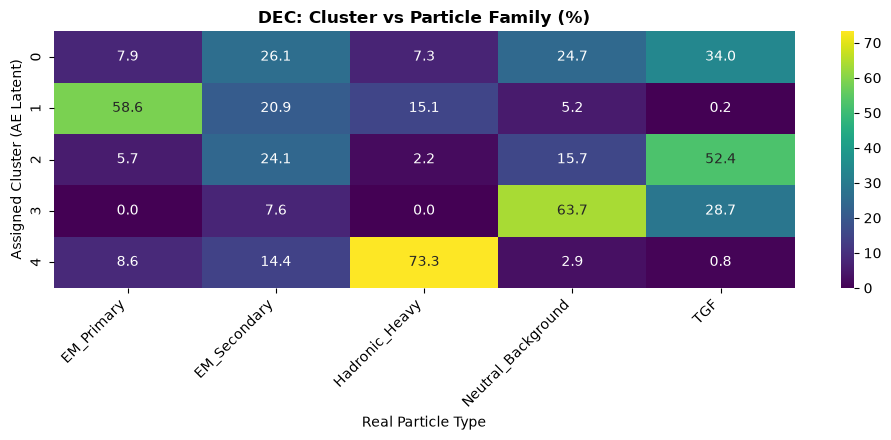

,Cluster,Count,Most Frequent Particle Type
0,0,356,TGF
1,1,536,EM_Primary
2,2,370,TGF
3,3,289,Neutral_Background
4,4,374,Hadronic_Heavy


In [22]:
ypred_test = dec.predict(Xtest_transformed)
print("test  acc:", acc(ytest, ypred_test))
plot_confusion_matrix(ytest, ypred_test, title_suffix="Particle Family" if FAMILY_CLUSTERING else "Particle Type", cluster_algo="DEC")
print_clustering_disribution(ypred_test, ytest)

# APPENDIX - Kernel-Bounded Clustering (KBC) tests

In [23]:
from kbc import KBC
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score

# psi_range = range(16, (128 + 16), 16) 
psi_range = range(64, (256 + 64), 64) 
tau_range = np.arange(0.1, 0.9, 0.1 )
k = len(np.unique(ytrain))

results = []
for psi in tqdm(psi_range, desc="Optimizing KBC hyperparameters"):
    for tau in tau_range:
        m = KBC(k=k, tau=tau, psi=psi, random_state=42).fit(Xtrain_transformed)
        lab = m.labels_
        results.append((psi, tau, acc(ytrain, lab), adjusted_mutual_info_score(ytrain, lab), adjusted_rand_score(ytrain, lab)))
    # print(f"psi={psi} done.")

results_df = pd.DataFrame(results, columns=["psi", "tau", "acc", "ami", "ari"]) 
results_df

Optimizing KBC hyperparameters: 100%|██████████| 4/4 [02:00<00:00, 30.08s/it]


,psi,tau,acc,ami,ari
0,64,0.1,0.594805,0.344415,0.302605
1,64,0.2,0.489091,0.326649,0.272134
2,64,0.3,0.555455,0.346221,0.269268
3,64,0.4,0.575584,0.337959,0.295608
4,64,0.5,0.586364,0.350868,0.295764
5,64,0.6,0.563636,0.335546,0.278265
6,64,0.7,0.582468,0.342773,0.300588
7,64,0.8,0.533506,0.284677,0.238066
8,128,0.1,0.542727,0.299952,0.238724
9,128,0.2,0.600909,0.338916,0.287433


In [24]:
results_df.sort_values(by="acc", ascending=False).head(5)

,psi,tau,acc,ami,ari
9,128,0.2,0.600909,0.338916,0.287433
0,64,0.1,0.594805,0.344415,0.302605
20,192,0.5,0.591299,0.362624,0.297241
4,64,0.5,0.586364,0.350868,0.295764
10,128,0.3,0.582597,0.345399,0.302914


Best parameters: tau=0.2, psi=128


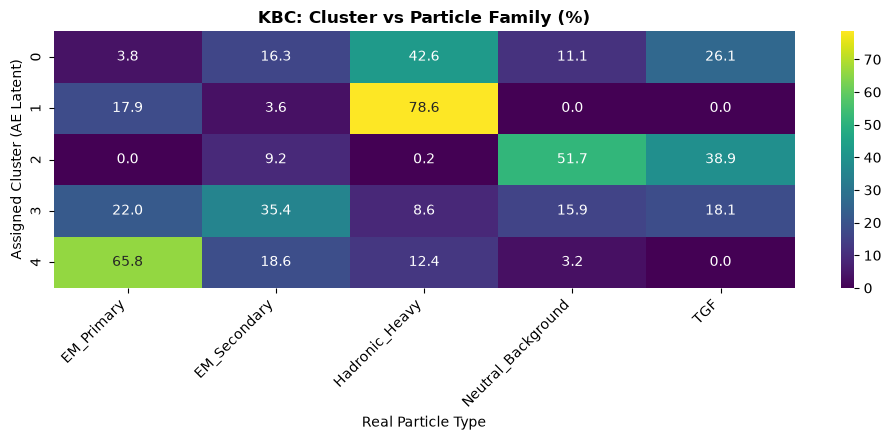

,Cluster,Count,Most Frequent Particle Type
0,0,601,Hadronic_Heavy
1,1,56,Hadronic_Heavy
2,2,424,Neutral_Background
3,3,441,EM_Secondary
4,4,403,EM_Primary


In [25]:
best_tau = results_df.loc[results_df['acc'].idxmax(), 'tau']
best_psi = results_df.loc[results_df['acc'].idxmax(), 'psi']
print(f"Best parameters: tau={best_tau}, psi={best_psi}")
ypred = KBC(k=k, tau=best_tau, psi=best_psi, random_state=42).fit(Xtest_transformed).labels_
plot_confusion_matrix(ytest, ypred, title_suffix="Particle Family" if FAMILY_CLUSTERING else "Particle Type", cluster_algo="KBC")
print_clustering_disribution(ypred, ytest)